# Sistema Inteligente para Priorização de Chamados de Manutenção

**Engenharia de Computação · Disciplina de Inteligência Artificial**

**Autor e único integrante: Guilherme Costa**

Todos os chamados são fictícios. O problema de prioridade foi construído a partir de uma política conhecida; por isso, o baseline de regras é uma referência mais forte que a classe majoritária. Neste cenário, não há justificativa operacional para substituir a política estável por ML. O objetivo dos modelos aprendidos é estudar avaliação por famílias, incerteza condicional, interpretabilidade, erros e robustez a ruído. O experimento de texto aborda uma tarefa distinta: sugerir equipe pela descrição.

Este notebook contém dados, árvore original e fontes dos experimentos. Não depende de upload manual nem de acesso ao repositório durante a execução. Nenhuma chamada à OpenAI é realizada. O Colab é compatível; as saídas entregues foram verificadas em kernel local limpo com `nbclient`.

## 1. Ambiente reproduzível e isolamento

As dependências têm versões fixadas. Somente a instalação de pacotes, quando necessária, exige internet. Os experimentos rodam em uma pasta temporária nova: não escrevem sobre o banco local, uploads ou árvore do aplicativo. Os resultados são regenerados a partir das fontes incorporadas, sem carregar relatórios previamente calculados.

In [1]:
import importlib.metadata as metadata
import subprocess
import sys
PACOTES = {"numpy": "2.3.5", "scipy": "1.17.0", "pandas": "2.2.3", "scikit-learn": "1.8.0", "joblib": "1.5.3", "matplotlib": "3.10.8", "Flask": "3.1.2", "requests": "2.34.2"}
instalar = []
for nome, versao in PACOTES.items():
    try:
        if metadata.version(nome) != versao:
            instalar.append(f"{nome}=={versao}")
    except metadata.PackageNotFoundError:
        instalar.append(f"{nome}=={versao}")
if instalar:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *instalar], check=True)
print({nome: metadata.version(nome) for nome in PACOTES})

{'numpy': '2.3.5', 'scipy': '1.17.0', 'pandas': '2.2.3', 'scikit-learn': '1.8.0', 'joblib': '1.5.3', 'matplotlib': '3.10.8', 'Flask': '3.1.2', 'requests': '2.34.2'}


In [2]:
ZIP_BASE64 = '...'
MANIFESTO_FONTES = {'scripts/ml_comum.py': '4e6d0120c9b6109986daa930c4fd4f19f6a41f23e6b6c45eb00fb3d8ca2c1efe', 'scripts/avaliar_modelos.py': '0fd1412b1936f287dbb7046f223ff828cf9ea8efaa62477f5a343650cc9a2014', 'scripts/interpretar_arvore.py': '9edc8ca8aaa614c340a67c06d136d9f10770cdc94c76df43dd543ed8161bf164', 'scripts/analisar_fronteiras.py': '4f1ea7d5c871f7114fd22beb6a47a6b3c1f6f10912ce20568fcde0b58a622719', 'scripts/experimento_ruido.py': 'e7e0a9588a4003d1af0906756ba8c12dd3004f2019318ea7d688c9cd057452dc', 'scripts/curva_aprendizado.py': 'e9cbce18f14f454a3383ef5e5af37d765b0de7faa0dd29564d30ae19dd0ab0ea', 'scripts/treinar_texto.py': '22e75aeac71cbc965bf75e687e2faf4a69d69309d6406bc6aeb21e51bcb49ead', 'texto_equipe.py': '6f50ab2a86537cd672115d8f72ff2995e4b918ccfd38294461b9dc07a2763e5f', 'multimodal.py': '0ad206c274ab4dd5befbf7f75924757444b3a387b80c3c9cee5c88d8f47eacd1', 'storage.py': 'bda44b1fad27fde84d66f58b36d3bc9aab23222299112a5639881fb4bf0011db', 'dados/chamados_ficticios.csv': 'a3ea00850b8875cdd931b36417608f98510529518663981254fb97daaa76a0cc', 'dados/divisao_treino_teste.csv': '60eb1eec5ce68068b619904a0efc606da2ca7365ec4e22600191f28d08bbd3ca', 'modelo/arvore.json': 'fab3dc0c51256c048e4cc13df0311ede3af4fdbd4c671b2528d6ff07a5b63aec', 'modelo/arvore.joblib': 'cda185f9d8ed33c5c098737166f1b8a408122186946e724d92c525b5dc83c475'}
import base64
from hashlib import sha256
from io import BytesIO
import json
import os
from pathlib import Path
import tempfile
from zipfile import ZipFile
import pandas as pd
import numpy as np
from IPython.display import display, Image

PASTA_TEMPORARIA = tempfile.TemporaryDirectory(prefix="experimentos-chamados-")
RAIZ_EXP = Path(PASTA_TEMPORARIA.name)
with ZipFile(BytesIO(base64.b64decode(ZIP_BASE64))) as pacote:
    for nome in pacote.namelist():
        alvo = (RAIZ_EXP / nome).resolve()
        assert alvo.is_relative_to(RAIZ_EXP.resolve())
        alvo.parent.mkdir(parents=True, exist_ok=True)
        alvo.write_bytes(pacote.read(nome))
for nome, esperado in MANIFESTO_FONTES.items():
    assert sha256((RAIZ_EXP / nome).read_bytes()).hexdigest() == esperado
REL = RAIZ_EXP / "relatorios"
REL.mkdir(exist_ok=True)
MODELOS_ORIGINAIS = {nome: sha256((RAIZ_EXP / nome).read_bytes()).hexdigest() for nome in ("modelo/arvore.json", "modelo/arvore.joblib")}
AMBIENTE = dict(os.environ)
AMBIENTE["OPENAI_API_KEY"] = ""
AMBIENTE["MPLBACKEND"] = "Agg"
COMANDOS_EXECUTADOS = []

def executar_script(nome):
    resposta = subprocess.run([sys.executable, str(RAIZ_EXP / "scripts" / nome)], cwd=RAIZ_EXP, env=AMBIENTE, text=True, capture_output=True, check=True)
    COMANDOS_EXECUTADOS.append(nome)
    print(f"Concluído: python scripts/{nome}")
    return resposta

def carregar_json(nome):
    return json.loads((REL / nome).read_text(encoding="utf-8"))

def figura(nome, largura=900):
    display(Image(filename=str(REL / "figuras" / nome), width=largura))

print("Fontes e dados conferidos; execução isolada, sem relatórios pré-calculados.")

Fontes e dados conferidos; execução isolada, sem relatórios pré-calculados.


## 2. Problema, dados fictícios e política de rotulagem

X contém risco à segurança, interrupção de serviço essencial, pessoas afetadas, dias aguardando e recorrência. O alvo y é `prioridade`: 0 = normal, 1 = prioritário. IDs, descrições e famílias não entram nesses modelos numéricos.

A política atribui prioridade quando há risco, interrupção essencial, pelo menos 40 pessoas e 7 dias, ou recorrência com pelo menos 10 pessoas e 14 dias. Os limiares são pedagógicos. Variações da mesma família permanecem juntas. A primeira partição agrupada com semente 42 preserva os conjuntos originais; o teste reservado não participa de escolha de hiperparâmetros ou da decisão de integrar o modelo textual.

In [3]:
sys.path.insert(0, str(RAIZ_EXP))
from scripts.ml_comum import FEATURES, carregar_dados, divisao_original, politica, hash_dados_numericos
base = carregar_dados(RAIZ_EXP)
idx_treino, idx_teste = divisao_original(base)
assert not set(base.iloc[idx_treino].familia_cenario) & set(base.iloc[idx_teste].familia_cenario)
assert np.array_equal(base.prioridade.to_numpy(), politica(base))
display(pd.DataFrame([{"conjunto": nome, "registros": len(parte), "famílias": parte.familia_cenario.nunique(), "normais": int((parte.prioridade == 0).sum()), "prioritários": int((parte.prioridade == 1).sum())} for nome, parte in [("Base", base), ("Desenvolvimento", base.iloc[idx_treino]), ("Teste reservado", base.iloc[idx_teste])]]))
print("SHA256 dos dados numéricos:", hash_dados_numericos(base))
display(base.head())

,conjunto,registros,famílias,normais,prioritários
0,Base,120,30,57,63
1,Desenvolvimento,96,24,47,49
2,Teste reservado,24,6,10,14


SHA256 dos dados numéricos: 2cd2b7c295852715400220a5cc3fa2d1751c15b1ae79669f0db67d6e2d2a4f0a


,id,familia_cenario,descricao,risco_seguranca,servico_essencial_interrompido,pessoas_afetadas,dias_aguardando,recorrente,prioridade,justificativa_rotulo,origem,equipe_rotulo,equipe_justificativa
0,FIC-001,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,0,0,0,Baixo impacto segundo a política didática,fictícia,Triagem geral,Ferragem de porta: manutenção predial fora das...
1,FIC-002,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,2,0,0,Baixo impacto segundo a política didática,fictícia,Triagem geral,Ferragem de porta: manutenção predial fora das...
2,FIC-003,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,9,1,0,Baixo impacto segundo a política didática,fictícia,Triagem geral,Ferragem de porta: manutenção predial fora das...
3,FIC-004,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,20,1,0,Baixo impacto segundo a política didática,fictícia,Triagem geral,Ferragem de porta: manutenção predial fora das...
4,FIC-005,pintura_corredor,Pintura descascada sem umidade ou risco no cor...,0,0,2,3,0,0,Baixo impacto segundo a política didática,fictícia,Triagem geral,Pintura e acabamento predial.


## 3. Baselines e validação cruzada agrupada com incerteza

Comparamos Dummy de maioria, política de regras, árvore com profundidade 6, regressão logística com padronização e Random Forest. A validação principal usa somente o desenvolvimento, com cinco folds e dez sementes distintas. O pré-processamento é ajustado no treino de cada fold. Para continuidade, o teste reservado é avaliado separadamente; a árvore original do aplicativo é carregada sem regravação.

A média e o desvio-padrão amostral resumem métricas OOF agregadas por repetição. O bootstrap reamostra famílias inteiras, mantendo variações e repetições juntas. Seus intervalos são condicionais às famílias fictícias disponíveis: repetir folds não cria observações independentes. O histórico de escolha da profundidade também limita a interpretação desta avaliação de configurações fixas.

In [4]:
executar_script("avaliar_modelos.py")
comparacao = carregar_json("comparacao_modelos.json")
linhas = []
for modelo, registro in comparacao["modelos"].items():
    for metrica, resumo in registro["validacao_cruzada"].items():
        linhas.append({"modelo": modelo, "métrica": metrica, "média OOF": resumo["media"], "desvio-padrão": resumo["desvio_padrao"], "IC95% por famílias": resumo["ic95_bootstrap_familias"]})
display(pd.DataFrame(linhas))
display(pd.DataFrame({nome: registro["teste_reservado"] for nome, registro in comparacao["modelos"].items()}).T)
display(comparacao["protocolo"])
print("Famílias de desenvolvimento:", base.iloc[idx_treino].familia_cenario.nunique())

Concluído: python scripts/avaliar_modelos.py


,modelo,métrica,média OOF,desvio-padrão,IC95% por famílias
0,Dummy,sensibilidade,0.551020,0.000000,"[0.4449974489795918, 0.6679264150943395]"
1,Dummy,precisao,0.450000,0.000000,"[0.2825173902894491, 0.6206007896579683]"
2,Dummy,f1,0.495413,0.000000,"[0.35610415951146185, 0.6012590225981194]"
3,Dummy,f2,0.527344,0.000000,"[0.4117172262971796, 0.6191087498576067]"
4,Dummy,acuracia,0.427083,0.000000,"[0.35208333333333336, 0.5041666666666667]"
5,Regras,sensibilidade,1.000000,0.000000,"[1.0, 1.0]"
6,Regras,precisao,1.000000,0.000000,"[1.0, 1.0]"
7,Regras,f1,1.000000,0.000000,"[1.0, 1.0]"
8,Regras,f2,1.000000,0.000000,"[1.0, 1.0]"
9,Regras,acuracia,1.000000,0.000000,"[1.0, 1.0]"


,sensibilidade,precisao,f1,f2,acuracia
Dummy,1.000000,0.583333,0.736842,0.875000,0.583333
Regras,1.000000,1.000000,1.000000,1.000000,1.000000
Arvore,1.000000,1.000000,1.000000,1.000000,1.000000
Logistica,0.857143,1.000000,0.923077,0.882353,0.916667
RandomForest,1.000000,1.000000,1.000000,1.000000,1.000000


{'desenvolvimento': {'registros': 96,
  'familias': 24,
  'ids': ['FIC-001',
   'FIC-002',
   'FIC-003',
   'FIC-004',
   'FIC-005',
   'FIC-006',
   'FIC-007',
   'FIC-008',
   'FIC-009',
   'FIC-010',
   'FIC-011',
   'FIC-012',
   'FIC-017',
   'FIC-018',
   'FIC-019',
   'FIC-020',
   'FIC-021',
   'FIC-022',
   'FIC-023',
   'FIC-024',
   'FIC-029',
   'FIC-030',
   'FIC-031',
   'FIC-032',
   'FIC-033',
   'FIC-034',
   'FIC-035',
   'FIC-036',
   'FIC-037',
   'FIC-038',
   'FIC-039',
   'FIC-040',
   'FIC-041',
   'FIC-042',
   'FIC-043',
   'FIC-044',
   'FIC-045',
   'FIC-046',
   'FIC-047',
   'FIC-048',
   'FIC-049',
   'FIC-050',
   'FIC-051',
   'FIC-052',
   'FIC-053',
   'FIC-054',
   'FIC-055',
   'FIC-056',
   'FIC-057',
   'FIC-058',
   'FIC-059',
   'FIC-060',
   'FIC-061',
   'FIC-062',
   'FIC-063',
   'FIC-064',
   'FIC-065',
   'FIC-066',
   'FIC-067',
   'FIC-068',
   'FIC-073',
   'FIC-074',
   'FIC-075',
   'FIC-076',
   'FIC-077',
   'FIC-078',
   'FIC-079',

Famílias de desenvolvimento: 24


## 4. Árvore publicada e interpretabilidade

Interpretamos o estimador já usado no aplicativo, sem retreiná-lo. Importância por redução de impureza descreve esse ajuste e não demonstra causalidade. Nos domínios inteiros, um corte `<= 39,5` separa os mesmos valores que a condição `>= 40`. A tabela permite distinguir cortes numericamente diferentes de decisões realmente diferentes. A ordem dos testes pode reorganizar a expressão lógica sem mudar a regra.

Concluído: python scripts/interpretar_arvore.py
|--- servico_essencial_interrompido <= 0.50
|   |--- risco_seguranca <= 0.50
|   |   |--- pessoas_afetadas <= 39.50
|   |   |   |--- dias_aguardando <= 13.50
|   |   |   |   |--- class: 0
|   |   |   |--- dias_aguardando >  13.50
|   |   |   |   |--- recorrente <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- recorrente >  0.50
|   |   |   |   |   |--- pessoas_afetadas <= 9.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- pessoas_afetadas >  9.50
|   |   |   |   |   |   |--- class: 1
|   |   |--- pessoas_afetadas >  39.50
|   |   |   |--- dias_aguardando <= 6.50
|   |   |   |   |--- class: 0
|   |   |   |--- dias_aguardando >  6.50
|   |   |   |   |--- class: 1
|   |--- risco_seguranca >  0.50
|   |   |--- class: 1
|--- servico_essencial_interrompido >  0.50
|   |--- class: 1



,no,atributo,limiar_aprendido,primeiro_inteiro_ramo_direito,condicao_ramo_direito,limiar_politica_correspondente,equivalente_em_inteiros,interpretacao
0,0,servico_essencial_interrompido,0.5,1,servico_essencial_interrompido >= 1,1,True,Corte intermediário entre inteiros consecutivo...
1,1,risco_seguranca,0.5,1,risco_seguranca >= 1,1,True,Corte intermediário entre inteiros consecutivo...
2,2,pessoas_afetadas,39.5,40,pessoas_afetadas >= 40,40,True,Corte intermediário entre inteiros consecutivo...
3,3,dias_aguardando,13.5,14,dias_aguardando >= 14,14,True,Corte intermediário entre inteiros consecutivo...
4,5,recorrente,0.5,1,recorrente >= 1,1,True,Corte intermediário entre inteiros consecutivo...
5,7,pessoas_afetadas,9.5,10,pessoas_afetadas >= 10,10,True,Corte intermediário entre inteiros consecutivo...
6,10,dias_aguardando,6.5,7,dias_aguardando >= 7,7,True,Corte intermediário entre inteiros consecutivo...


,atributo,importancia
0,risco_seguranca,0.227175
1,servico_essencial_interrompido,0.252417
2,pessoas_afetadas,0.214453
3,dias_aguardando,0.223936
4,recorrente,0.082019


A árvore recuperou a política nos domínios inteiros verificados. Os cortes 39,5/6,5 e 9,5/13,5 equivalem a pessoas >= 40 e dias >= 7, ou pessoas >= 10 e dias >= 14; 0,5 separa os indicadores 0/1. A ordem dos testes reorganiza a expressão lógica. Não se trata de descoberta de critérios reais: os rótulos foram gerados pela própria política.


{'representantes': 512,
 'divergencias': 0,
 'natureza': 'Verificação de consistência em representantes das células dos cortes; não validação externa.'}

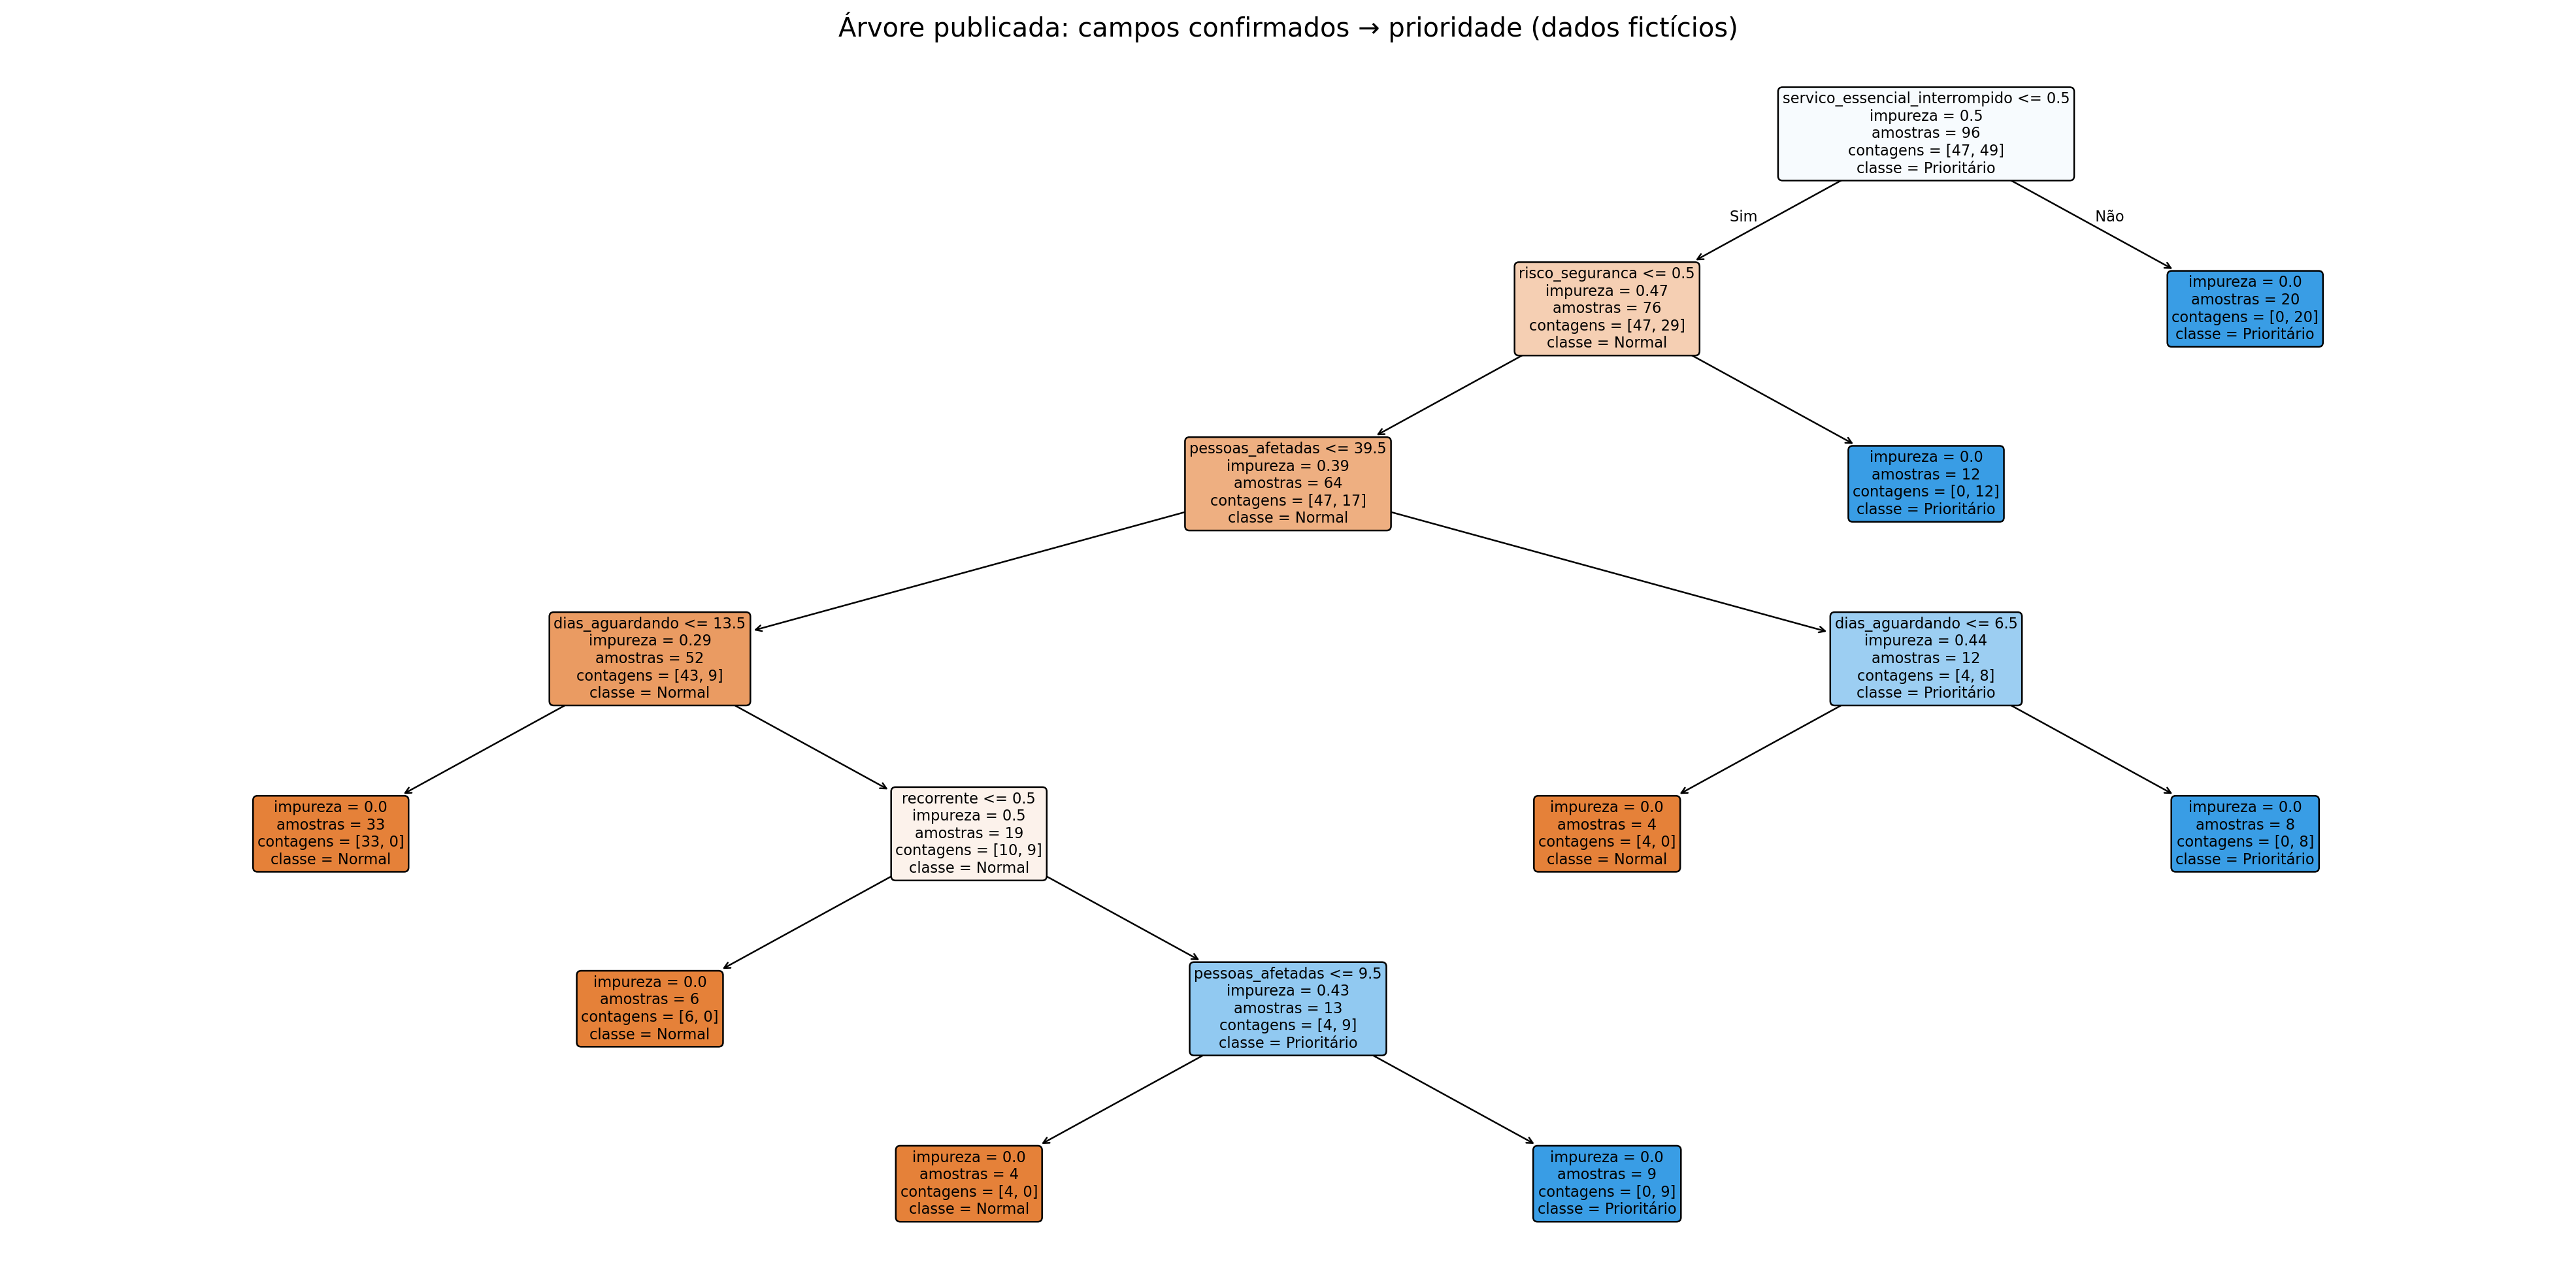

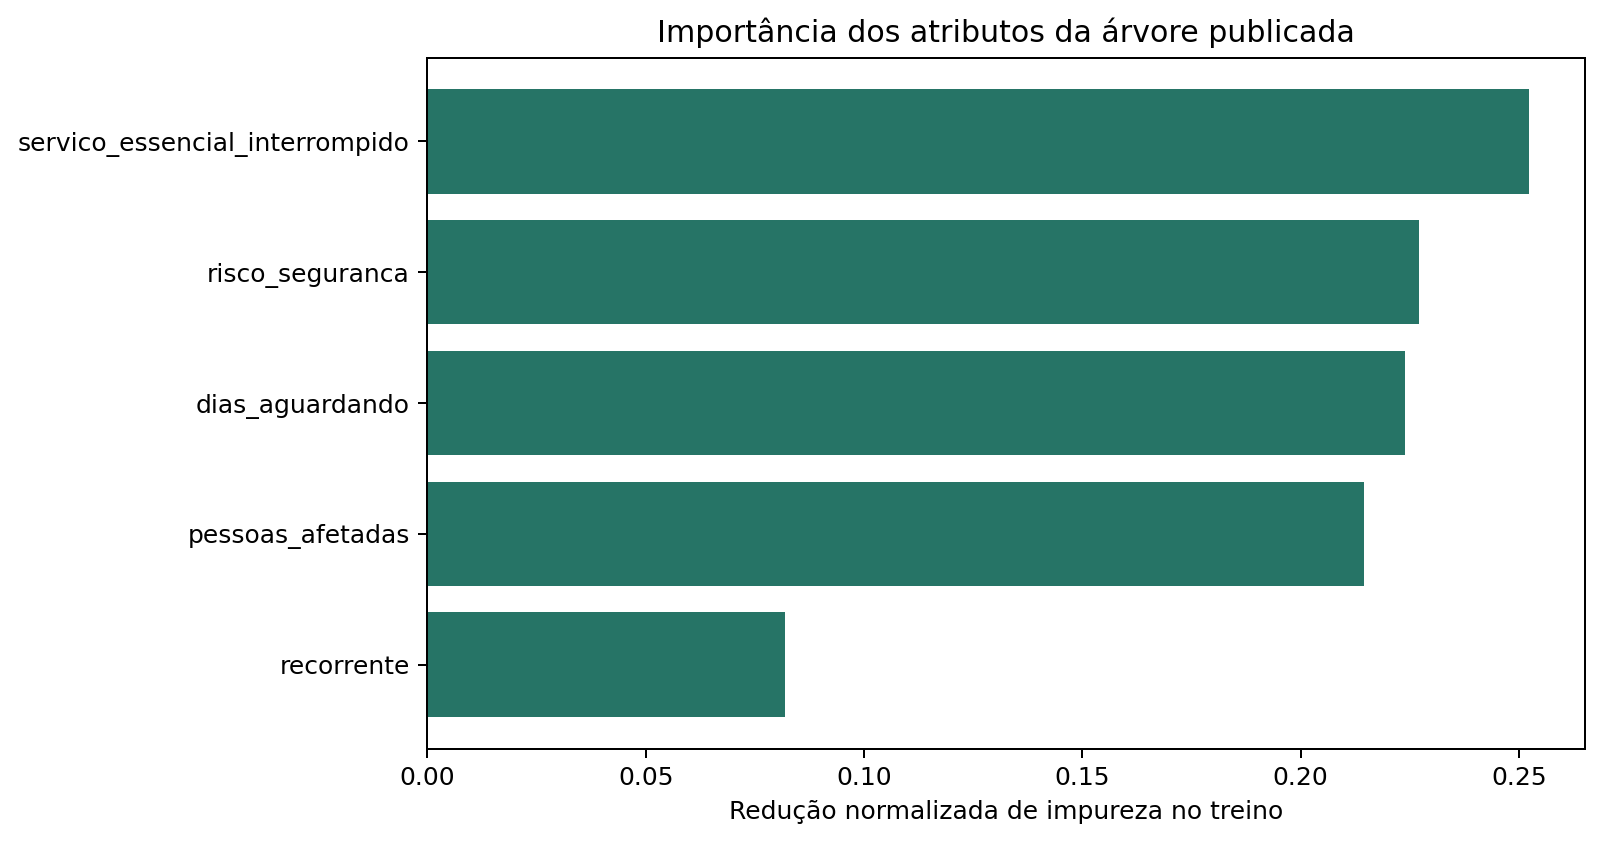

In [5]:
executar_script("interpretar_arvore.py")
interpretacao = carregar_json("interpretabilidade.json")
print((REL / "arvore_interpretada.txt").read_text(encoding="utf-8"))
display(pd.DataFrame(interpretacao["limiares"]))
display(pd.DataFrame(interpretacao["importancias"]))
print(interpretacao["interpretacao"])
display(interpretacao["consistencia_celulas"])
figura("arvore_publicada.png", 1100)
figura("importancias_arvore.png")

## 5. Fronteiras da política e análise de erros fora da amostra

A grade combina pessoas 8–12 e 38–42, dias 5–9 e 12–16 e os três indicadores binários. Ela foi derivada da própria política: mede consistência e cobertura de fronteiras, não validação externa. As taxas de falsos negativos usam como denominador os positivos de cada região; regiões sem positivos não permitem essa taxa.

Erros OOF são separados dos erros da grade. Cada previsão OOF foi produzida com a família correspondente fora do treino. O mesmo caso pode reaparecer em repetições; listagens e matrizes somadas não representam novos chamados independentes.

Concluído: python scripts/analisar_fronteiras.py


,sensibilidade,precisao,f1,f2,acuracia,registros,positivos_politica,divergencias,falsos_negativos,falsos_positivos,taxa_falsos_negativos
Dummy,1.000000,0.828750,0.906357,0.960313,0.82875,800.0,663.0,137.0,0.0,137.0,0.000000
Regras,1.000000,1.000000,1.000000,1.000000,1.00000,800.0,663.0,0.0,0.0,0.0,0.000000
Arvore,1.000000,1.000000,1.000000,1.000000,1.00000,800.0,663.0,0.0,0.0,0.0,0.000000
Logistica,0.950226,0.969231,0.959634,0.953967,0.93375,800.0,663.0,53.0,33.0,20.0,0.049774
RandomForest,0.990950,1.000000,0.995455,0.992747,0.99250,800.0,663.0,6.0,6.0,0.0,0.009050


,modelo,regiao_pessoas,regiao_dias,risco_seguranca,servico_essencial_interrompido,recorrente,registros,positivos_politica,divergencias,falsos_negativos,falsos_positivos,taxa_falsos_negativos
0,Dummy,38–42,12–16,0,0,0,25,15,10,0,10,0.0
1,Dummy,38–42,12–16,0,0,1,25,21,4,0,4,0.0
2,Dummy,38–42,12–16,0,1,0,25,25,0,0,0,0.0
3,Dummy,38–42,12–16,0,1,1,25,25,0,0,0,0.0
4,Dummy,38–42,12–16,1,0,0,25,25,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
155,RandomForest,8–12,5–9,0,1,1,25,25,0,0,0,0.0
156,RandomForest,8–12,5–9,1,0,0,25,25,0,0,0,0.0
157,RandomForest,8–12,5–9,1,0,1,25,25,0,0,0,0.0
158,RandomForest,8–12,5–9,1,1,0,25,25,0,0,0,0.0


A árvore não divergiu da política nesta grade.
Previsões OOF erradas, incluindo repetições: 763


,modelo,tipo_erro,ocorrências
0,Arvore,falso_negativo,9
1,Arvore,falso_positivo,19
2,Dummy,falso_negativo,220
3,Dummy,falso_positivo,330
4,Logistica,falso_negativo,143
5,Logistica,falso_positivo,27
6,RandomForest,falso_positivo,15


,modelo,repeticao,seed,fold,id,familia_cenario,descricao,risco_seguranca,servico_essencial_interrompido,pessoas_afetadas,dias_aguardando,recorrente,prioridade,previsto,tipo_erro
0,Dummy,0,42,4,FIC-001,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,0,0,0,1,falso_positivo
1,Dummy,0,42,4,FIC-002,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,2,0,0,1,falso_positivo
2,Dummy,0,42,4,FIC-003,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,9,1,0,1,falso_positivo
3,Dummy,0,42,4,FIC-004,macaneta_sala_vazia,"Maçaneta frouxa em sala desocupada, sem risco ...",0,0,0,20,1,0,1,falso_positivo
4,Dummy,0,42,0,FIC-009,lampada_deposito,Lâmpada de depósito falhou; iluminação alterna...,0,0,1,1,0,0,1,falso_positivo
5,Dummy,0,42,0,FIC-010,lampada_deposito,Lâmpada de depósito falhou; iluminação alterna...,0,0,2,4,0,0,1,falso_positivo
6,Dummy,0,42,0,FIC-011,lampada_deposito,Lâmpada de depósito falhou; iluminação alterna...,0,0,4,8,0,0,1,falso_positivo
7,Dummy,0,42,0,FIC-012,lampada_deposito,Lâmpada de depósito falhou; iluminação alterna...,0,0,0,18,1,0,1,falso_positivo
8,Dummy,0,42,4,FIC-017,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,0,0,0,2,0,0,1,falso_positivo
9,Dummy,0,42,4,FIC-018,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,0,0,12,3,1,0,1,falso_positivo


A lista completa está em relatorios/erros_oof_modelos.csv desta execução.


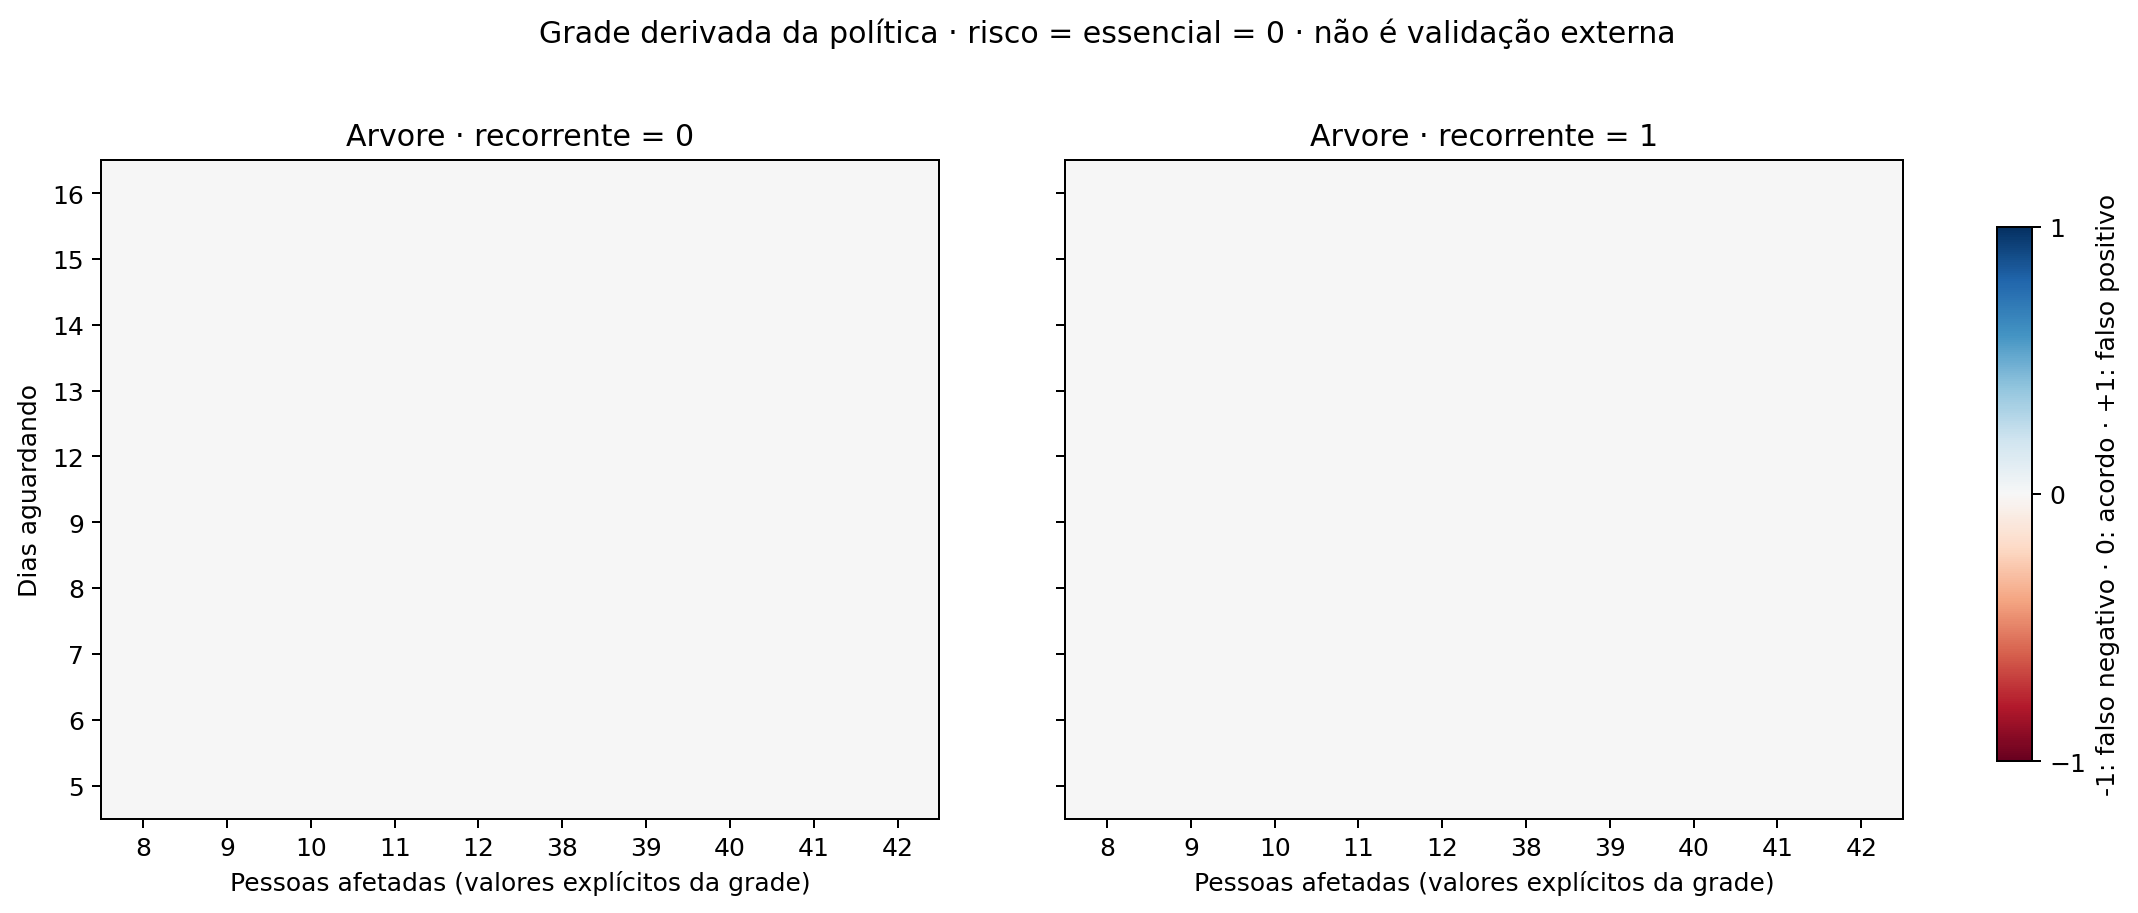

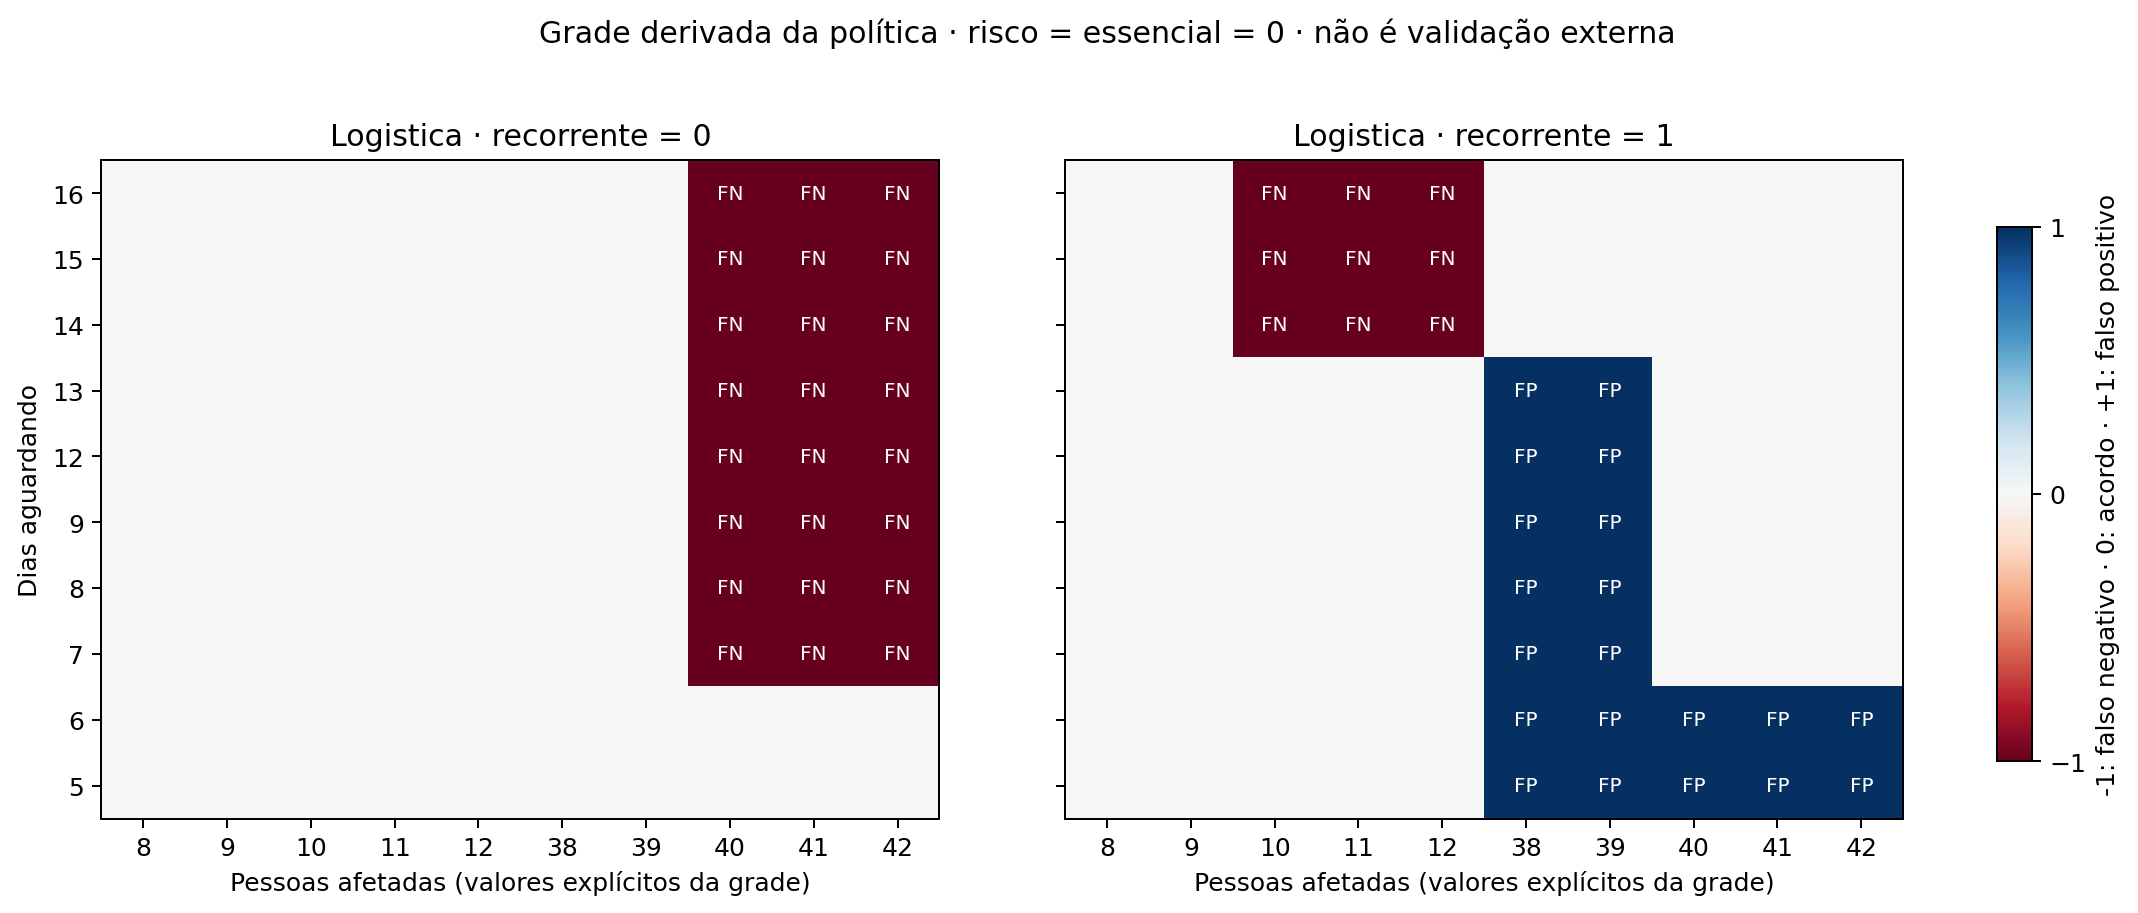

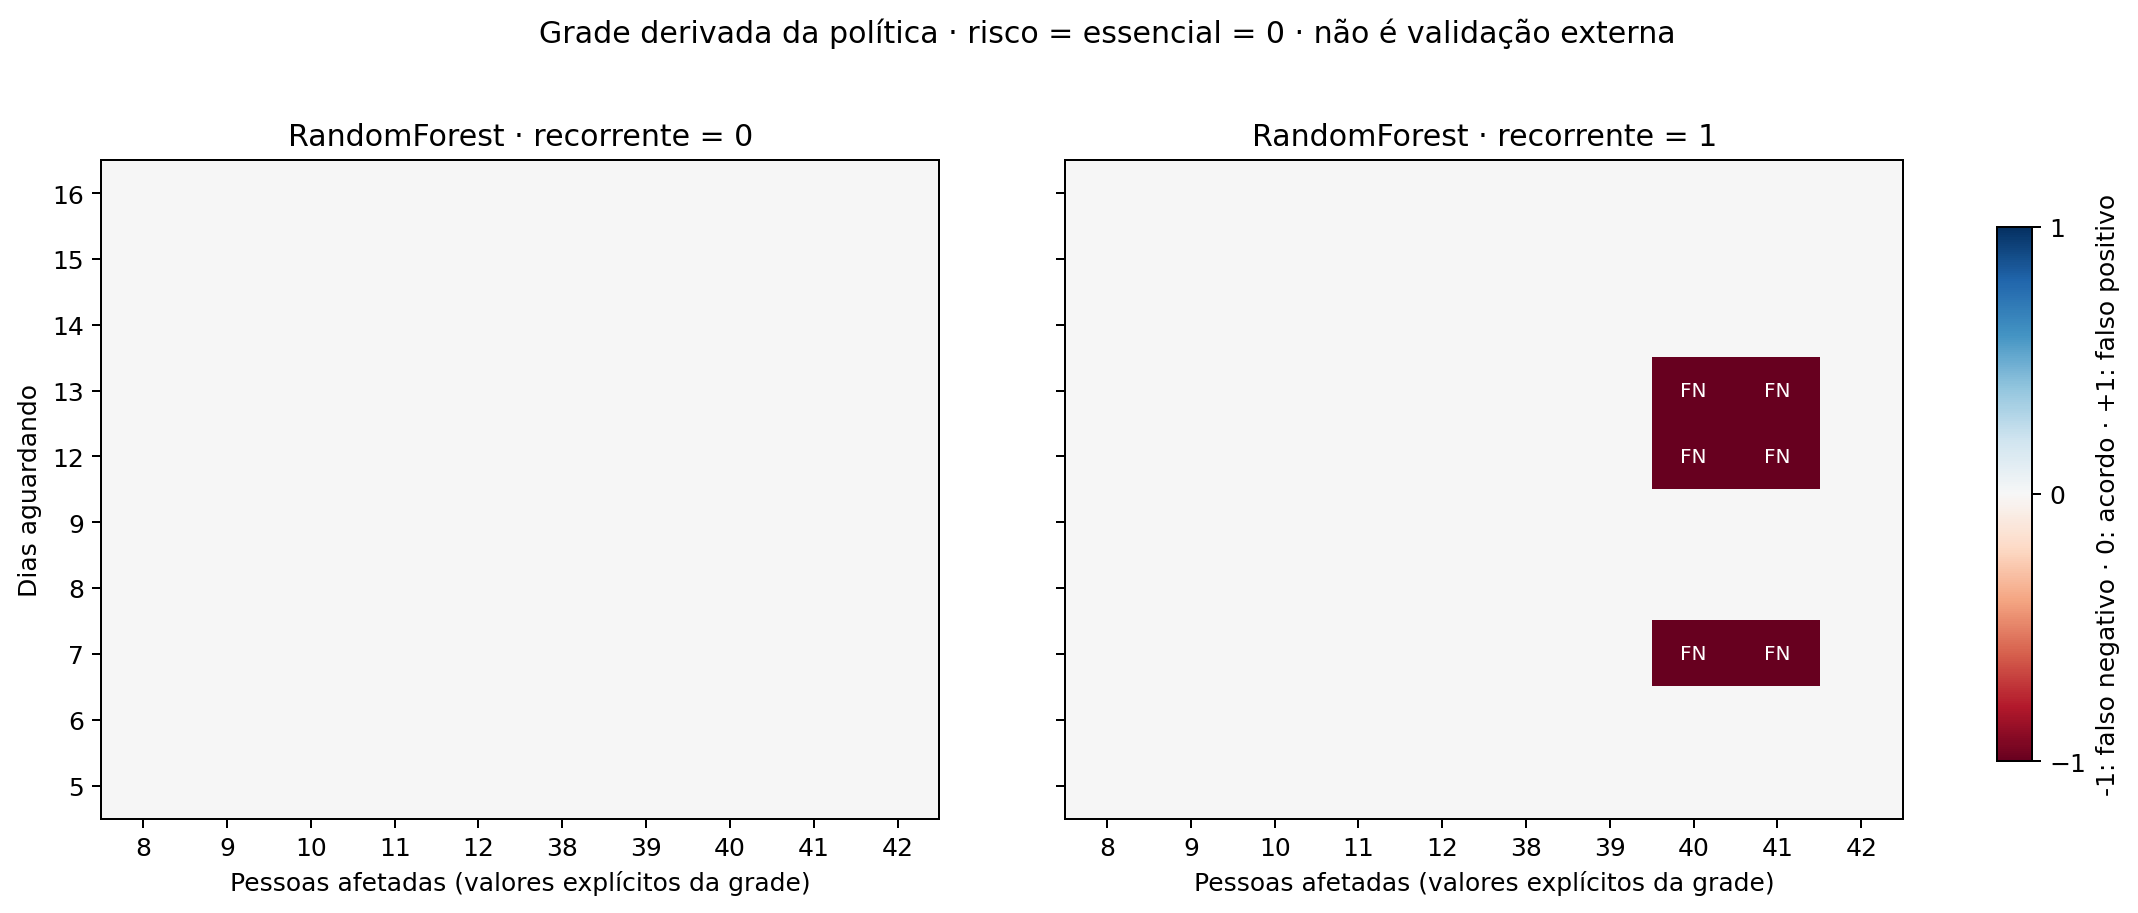

In [6]:
executar_script("analisar_fronteiras.py")
fronteiras = carregar_json("fronteiras.json")
display(pd.DataFrame(fronteiras["modelos"]).T)
display(pd.DataFrame(fronteiras["taxas_por_regiao"]))
print(fronteiras["interpretacao"])
erros = pd.DataFrame(comparacao["erros_oof"])
print("Previsões OOF erradas, incluindo repetições:", len(erros))
if len(erros):
    display(erros.groupby(["modelo", "tipo_erro"]).size().rename("ocorrências").reset_index())
    display(erros.head(30))
    print("A lista completa está em relatorios/erros_oof_modelos.csv desta execução.")
else:
    print("Nenhum erro OOF observado neste protocolo; isso não garante ausência de erro real.")
for nome in ("fronteiras_arvore.png", "fronteiras_logistica.png", "fronteiras_randomforest.png"):
    figura(nome)

## 6. Experimento de ruído nos rótulos

Invertemos rótulos somente no treino original e avaliamos no teste reservado limpo. Comparamos ruído uniforme e concentrado nas fronteiras, com o mesmo número de inversões por taxa e semente. A unidade é o registro; os dados originais permanecem intactos. As taxas nominais de 0%, 5%, 10%, 15% e 20% são acompanhadas das taxas efetivas após arredondamento.

Além dos modelos anteriores, testamos árvore limitada a profundidade 3 e árvore cuja profundidade é escolhida por GridSearchCV agrupado exclusivamente no treino ruidoso. O baseline de regras ignora rótulos de treino por definição. O desacordo de fronteira é uma simulação escolhida pelo autor, não uma estimativa de como pessoas reais rotulariam chamados.

Concluído: python scripts/experimento_ruido.py


,modelo,modo,taxa nominal,taxa efetiva,sensibilidade_media,sensibilidade_desvio_padrao,precisao_media,precisao_desvio_padrao,f1_media,f1_desvio_padrao,f2_media,f2_desvio_padrao,acuracia_media,acuracia_desvio_padrao
0,Dummy,uniforme,0.0,0.000000,1.000000,0.000000,0.583333,1.139065e-16,0.736842,1.139065e-16,0.875000,0.000000e+00,0.583333,1.139065e-16
1,Regras,uniforme,0.0,0.000000,1.000000,0.000000,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00
2,Arvore,uniforme,0.0,0.000000,1.000000,0.000000,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00
3,Logistica,uniforme,0.0,0.000000,0.857143,0.000000,1.000000,0.000000e+00,0.923077,0.000000e+00,0.882353,1.139065e-16,0.916667,1.139065e-16
4,RandomForest,uniforme,0.0,0.000000,1.000000,0.000000,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00,1.000000,0.000000e+00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,Arvore,fronteira,0.2,0.197917,0.885714,0.067166,0.928353,8.418393e-02,0.902440,4.293575e-02,0.891329,4.972394e-02,0.887500,5.076174e-02
66,Logistica,fronteira,0.2,0.197917,0.860714,0.015972,0.990625,4.192627e-02,0.920256,1.261372e-02,0.883374,4.567132e-03,0.912500,1.863390e-02
67,RandomForest,fronteira,0.2,0.197917,0.892857,0.043355,0.839501,5.330574e-02,0.863934,3.251600e-02,0.880687,3.426007e-02,0.835417,4.161181e-02
68,ArvoreLimitada,fronteira,0.2,0.197917,0.857143,0.000000,1.000000,0.000000e+00,0.923077,0.000000e+00,0.882353,1.139065e-16,0.916667,1.139065e-16


{'unidade_corrupcao': 'registro, não família',
 'seeds_ruido': [42,
  43,
  44,
  45,
  46,
  47,
  48,
  49,
  50,
  51,
  52,
  53,
  54,
  55,
  56,
  57,
  58,
  59,
  60,
  61],
 'seed_modelos': 42,
 'separacao': 'primeira partição StratifiedGroupKFold 5, seed 42',
 'taxas_nominais': [0.0, 0.05, 0.1, 0.15, 0.2],
 'arredondamento': 'round(taxa * n_treino); mesma quantidade nos dois modos',
 'treino_ids': ['FIC-001',
  'FIC-002',
  'FIC-003',
  'FIC-004',
  'FIC-005',
  'FIC-006',
  'FIC-007',
  'FIC-008',
  'FIC-009',
  'FIC-010',
  'FIC-011',
  'FIC-012',
  'FIC-017',
  'FIC-018',
  'FIC-019',
  'FIC-020',
  'FIC-021',
  'FIC-022',
  'FIC-023',
  'FIC-024',
  'FIC-029',
  'FIC-030',
  'FIC-031',
  'FIC-032',
  'FIC-033',
  'FIC-034',
  'FIC-035',
  'FIC-036',
  'FIC-037',
  'FIC-038',
  'FIC-039',
  'FIC-040',
  'FIC-041',
  'FIC-042',
  'FIC-043',
  'FIC-044',
  'FIC-045',
  'FIC-046',
  'FIC-047',
  'FIC-048',
  'FIC-049',
  'FIC-050',
  'FIC-051',
  'FIC-052',
  'FIC-053',
  'F

,modo,taxa,frequências
0,uniforme,0.00,{'6': 20}
1,uniforme,0.05,"{'6': 8, 'sem_limite': 9, '5': 3}"
2,uniforme,0.10,"{'6': 8, '5': 4, 'sem_limite': 8}"
3,uniforme,0.15,"{'6': 6, '5': 4, 'sem_limite': 10}"
4,uniforme,0.20,"{'sem_limite': 14, '6': 3, '4': 1, '5': 2}"
5,fronteira,0.00,{'6': 20}
6,fronteira,0.05,"{'5': 3, '6': 7, 'sem_limite': 10}"
7,fronteira,0.10,"{'sem_limite': 9, '6': 7, '5': 2, '3': 1, '4': 1}"
8,fronteira,0.15,"{'6': 4, 'sem_limite': 10, '4': 1, '5': 3, '3'..."
9,fronteira,0.20,"{'sem_limite': 8, '4': 2, '5': 3, '3': 4, '6': 3}"


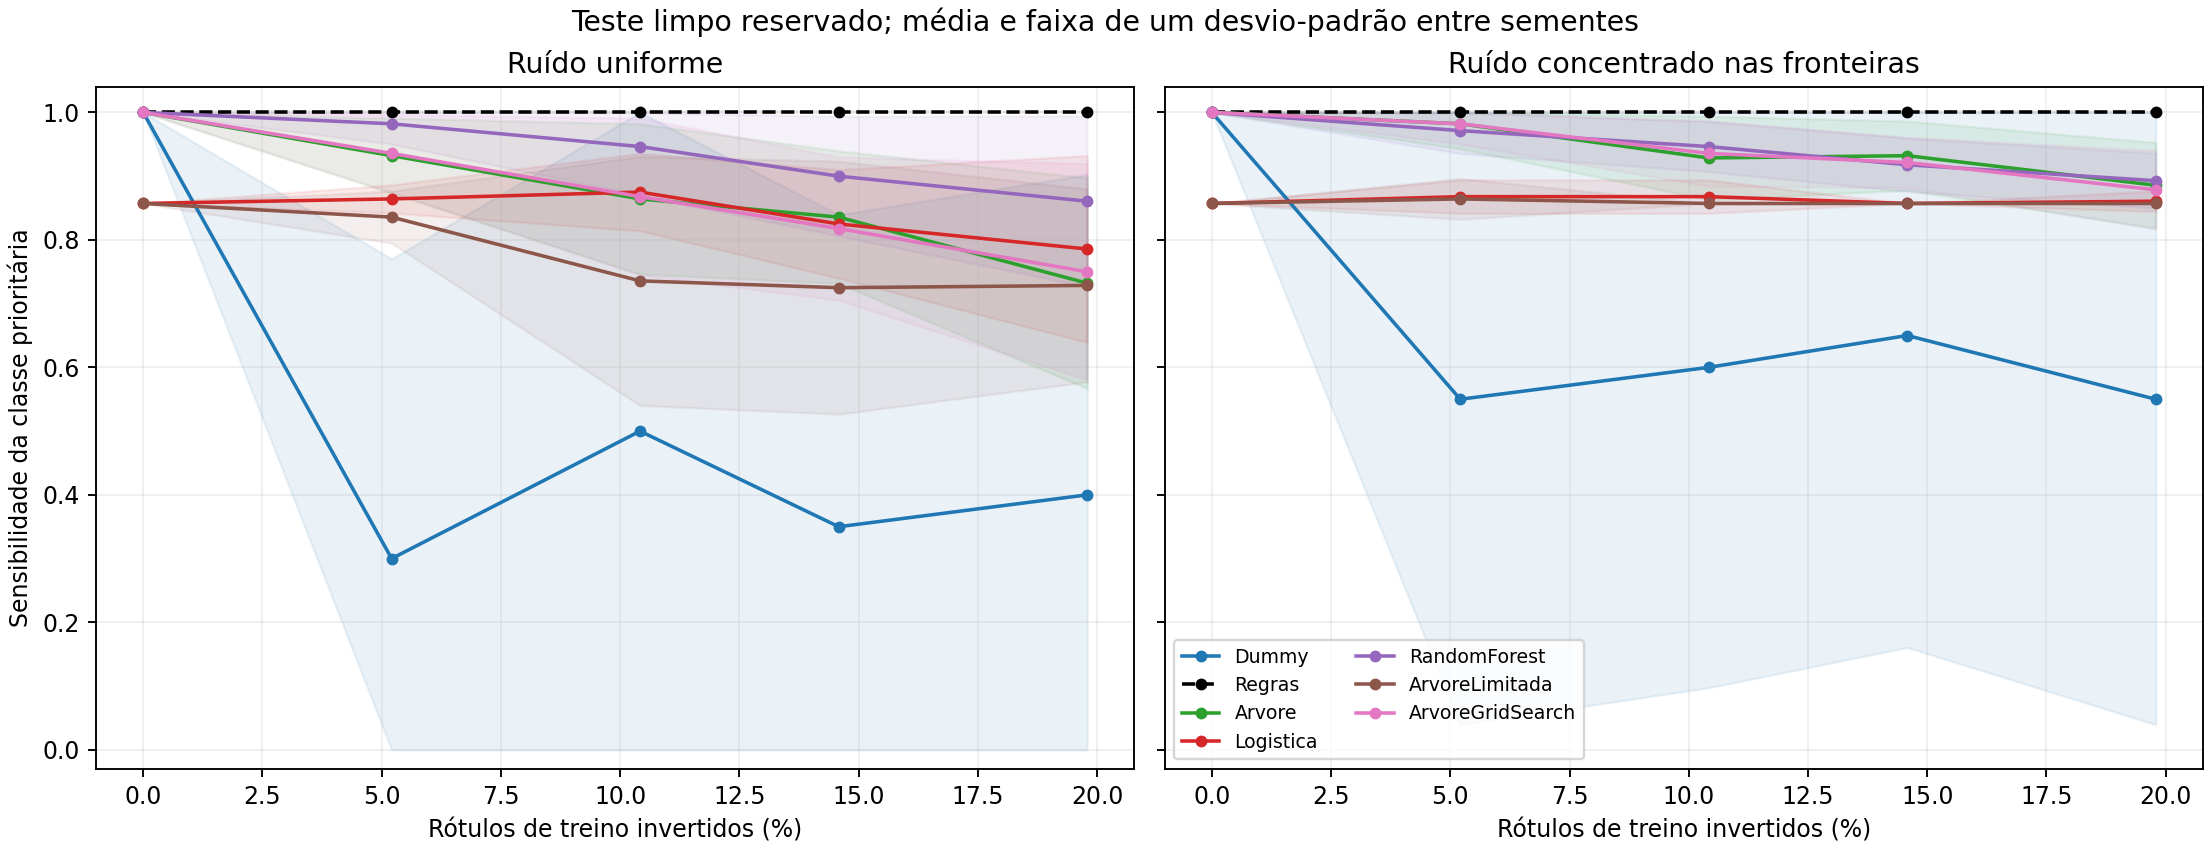

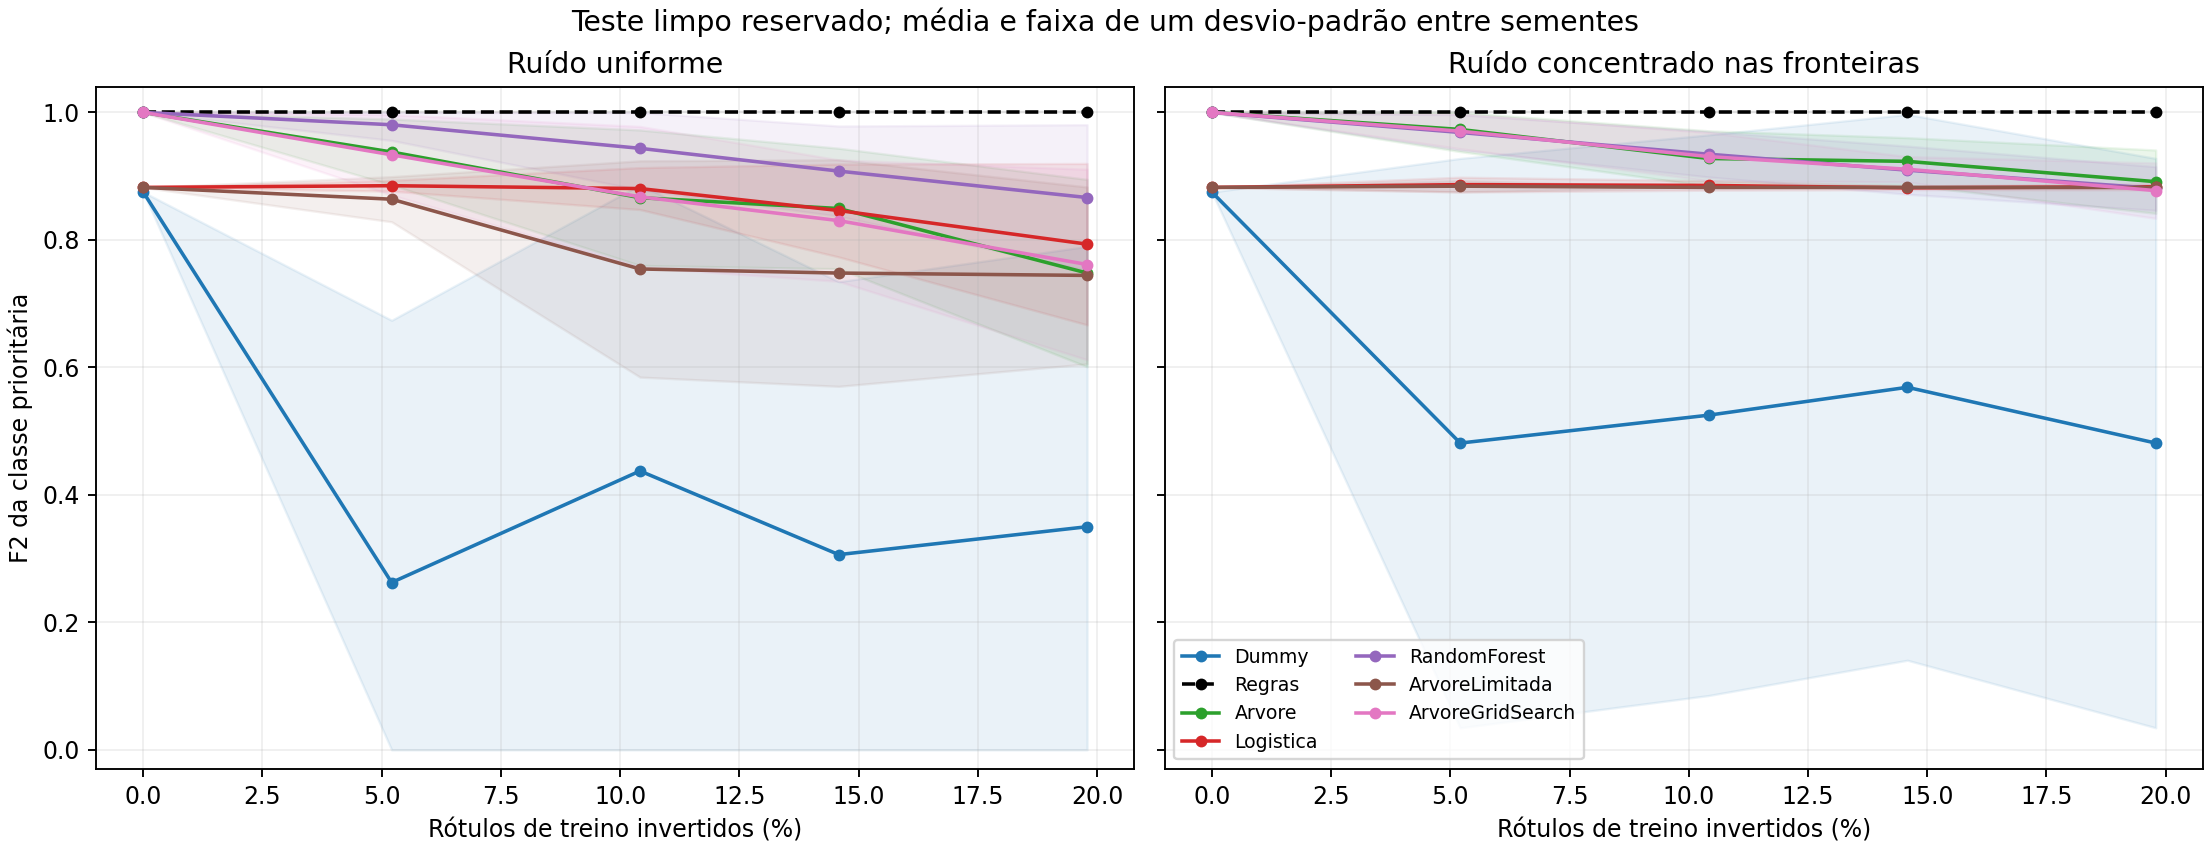

In [7]:
executar_script("experimento_ruido.py")
ruido = carregar_json("experimento_ruido.json")
resumo_ruido = []
for linha in ruido["resumo"]:
    resumo_ruido.append({"modelo": linha["modelo"], "modo": linha["modo"], "taxa nominal": linha["taxa_nominal"], "taxa efetiva": linha["taxa_efetiva"], **{f"{m}_{k}": v for m, registro in linha["metricas"]["teste_limpo"].items() for k, v in registro.items()}})
display(pd.DataFrame(resumo_ruido))
display(ruido["protocolo"])
profundidades = [{"modo": r["modo"], "taxa": r["taxa_nominal"], "frequências": r.get("frequencia_max_depth_escolhido", {})} for r in ruido["resumo"] if "Grid" in r["modelo"] or r.get("frequencia_max_depth_escolhido")]
display(pd.DataFrame(profundidades))
figura("ruido_sensibilidade.png", 1000)
figura("ruido_f2.png", 1000)

### Como interpretar robustez e overfitting

Compare treino ruidoso, treino limpo e teste limpo, além das faixas de desvio nos gráficos. Maior ajuste aos rótulos perturbados com pior desempenho limpo é evidência de sensibilidade ao ruído neste experimento. Não se deve afirmar que limitar profundidade ou trocar algoritmo sempre melhora: essa conclusão depende dos resultados medidos, do modo de perturbação e das famílias do teste. A configuração vencedora sob ruído não será promovida ao aplicativo com base neste teste reutilizado.

## 7. Curva de aprendizado por número de famílias

Subconjuntos aninhados de famílias do treino são usados para ajustar árvore e regressão logística, mantendo famílias externas para validação. O teste reservado não entra nesta curva. A dispersão entre partições sobrepostas é descritiva, e a curva pode não ser monotônica.

Um patamar em exemplos rotulados por regras não comprova que a quantidade atual de dados baste para uma instituição. A aquisição de famílias independentes e rótulos revisados por especialistas continua necessária.

Concluído: python scripts/curva_aprendizado.py


,modelo,familias_treino,registros_treino,avaliacoes,treino · sensibilidade · media,treino · sensibilidade · desvio_padrao,treino · precisao · media,treino · precisao · desvio_padrao,treino · f1 · media,treino · f1 · desvio_padrao,...,validacao · sensibilidade · media,validacao · sensibilidade · desvio_padrao,validacao · precisao · media,validacao · precisao · desvio_padrao,validacao · f1 · media,validacao · f1 · desvio_padrao,validacao · f2 · media,validacao · f2 · desvio_padrao,validacao · acuracia · media,validacao · acuracia · desvio_padrao
0,Arvore,4,16,25,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.541333,0.301262,0.749584,0.316469,0.606980,0.284207,0.562366,0.291291,0.7190,0.141703
1,Arvore,8,32,25,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,...,0.769000,0.256873,0.866567,0.214814,0.793897,0.206026,0.774812,0.233273,0.8310,0.126867
2,Arvore,12,48,25,0.992208,0.019188,0.993640,0.015067,0.992751,0.011392,...,0.848556,0.243985,0.896512,0.106831,0.847271,0.165664,0.844131,0.213500,0.8680,0.115644
3,Arvore,16,64,25,0.995040,0.014735,0.982599,0.038832,0.988297,0.020748,...,0.890778,0.184495,0.942378,0.075131,0.902046,0.132604,0.893529,0.165941,0.9155,0.099562
4,Arvore,19,76,25,0.998919,0.005405,0.981102,0.036655,0.989572,0.019107,...,0.980556,0.058101,0.964698,0.058994,0.970978,0.046610,0.976350,0.051289,0.9715,0.041382
5,Logistica,4,16,25,0.796333,0.208654,0.897424,0.132525,0.826933,0.152692,...,0.570667,0.358844,0.687162,0.357947,0.578026,0.318910,0.565627,0.333584,0.6965,0.141813
6,Logistica,8,32,25,0.731535,0.126312,0.952077,0.070412,0.820707,0.086614,...,0.638889,0.204990,0.901074,0.167799,0.729006,0.166238,0.669161,0.189063,0.7850,0.095743
7,Logistica,12,48,25,0.710580,0.111327,0.943539,0.068844,0.803325,0.066415,...,0.656333,0.178250,0.917524,0.138742,0.747875,0.134893,0.687682,0.161967,0.7950,0.087202
8,Logistica,16,64,25,0.678047,0.061469,0.951732,0.037506,0.790795,0.050344,...,0.664333,0.160523,0.944190,0.107315,0.766084,0.121735,0.699741,0.147314,0.8110,0.073626
9,Logistica,19,76,25,0.704797,0.033034,0.952289,0.023027,0.809746,0.027034,...,0.699333,0.153660,0.938857,0.097354,0.789949,0.115077,0.731312,0.140081,0.8270,0.066112


{'desenvolvimento_registros': 96,
 'desenvolvimento_familias': 24,
 'teste_reservado_usado': False,
 'ids_reservados_excluidos': ['FIC-013',
  'FIC-014',
  'FIC-015',
  'FIC-016',
  'FIC-025',
  'FIC-026',
  'FIC-027',
  'FIC-028',
  'FIC-069',
  'FIC-070',
  'FIC-071',
  'FIC-072',
  'FIC-081',
  'FIC-082',
  'FIC-083',
  'FIC-084',
  'FIC-101',
  'FIC-102',
  'FIC-103',
  'FIC-104',
  'FIC-109',
  'FIC-110',
  'FIC-111',
  'FIC-112'],
 'familias_reservadas_excluidas': ['armario_auxiliar',
  'cadeira_estofado',
  'cozinha_sem_refrigeracao',
  'forro_solto',
  'piso_escorregadio',
  'torneira_auxiliar'],
 'validacao': 'StratifiedGroupKFold de cinco folds repetido com sementes distintas, somente no desenvolvimento',
 'seeds_particoes': [42, 43, 44, 45, 46],
 'seed_modelos': 42,
 'quantidade_particoes': 25,
 'tamanhos_solicitados_familias': [4, 8, 12, 16, 19],
 'subamostragem': 'Prefixos aninhados de ordem de famílias embaralhada por seed*100+fold; cobertura das duas classes no menor pre

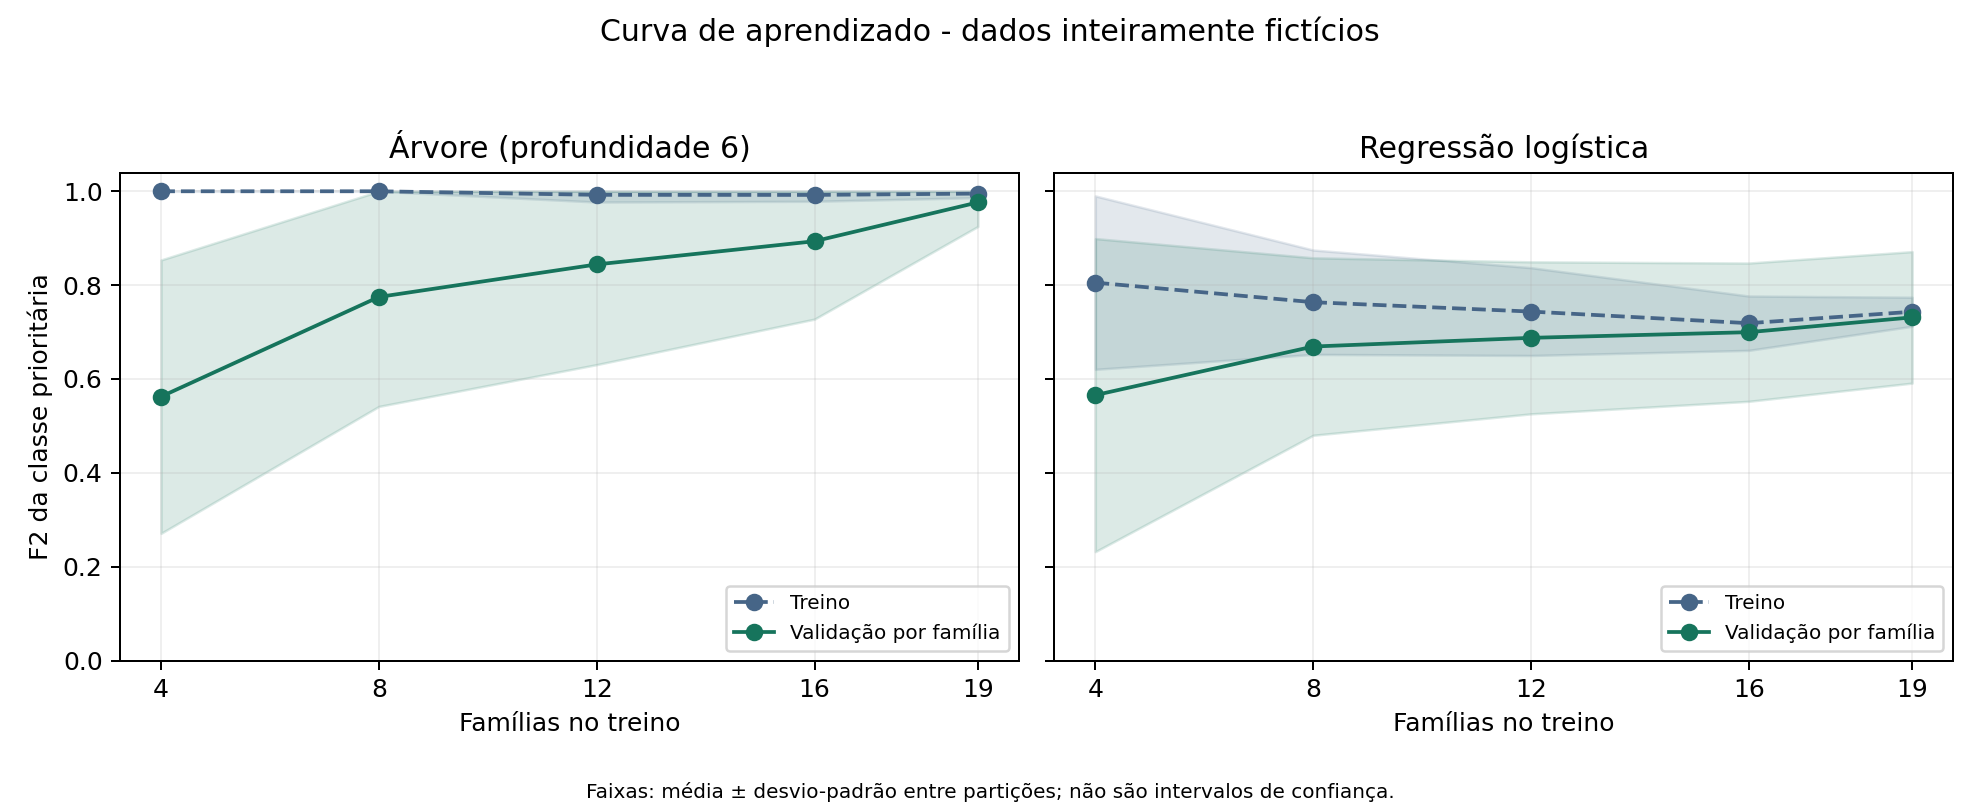

In [8]:
executar_script("curva_aprendizado.py")
curva = carregar_json("curva_aprendizado.json")
display(pd.json_normalize(curva["resumos"], sep=" · "))
display(curva["protocolo"])
figura("curva_aprendizado.png")

## 8. Classificador de texto para equipe

Cada família recebe uma anotação didática manual de equipe e uma justificativa. A entrada é somente a descrição; o sufixo sintético com contagens é removido antes da vetorização. O pipeline combina TF-IDF de palavras/bigramas e de n-gramas de caracteres com regressão logística. TF-IDF e classificador são ajustados dentro de cada fold agrupado.

Comparamos a regra local de palavras-chave nas mesmas partições de desenvolvimento. A integração depende de superar estritamente a regra tanto em acurácia média quanto em F1 macro médio. O gate é decidido antes de consultar o reservado. Se não superar, o artefato textual continua experimental e a regra permanece no Flask. Texto e equipe jamais mudam a classificação de prioridade pela árvore.

In [9]:
executar_script("treinar_texto.py")
texto = carregar_json("classificador_texto.json")
linhas_texto = []
for nome, registro in texto["modelos"].items():
    linhas_texto.append({"modelo": nome, **{f"{m}_{k}": v for m in ("acuracia", "f1_macro") for k, v in registro[m].items()}})
    print(nome, "matriz OOF somada; ordem das classes:", texto["ordem_classes"])
    display(pd.DataFrame(registro["matriz_confusao_oof_somada"], index=texto["ordem_classes"], columns=texto["ordem_classes"]))
    print("Erros OOF, incluindo repetições:", len(registro["erros_oof"]))
    display(pd.DataFrame(registro["erros_oof"]).head(12))
display(pd.DataFrame(linhas_texto))
display(texto["gate"])
display(texto["teste_reservado"])
display(texto.get("suporte_teste_reservado", {}))
print("A partição reservada foi estratificada por prioridade, não por equipe. Consulte o suporte por classe; o F1 macro usa a ordem fixa de quatro classes, inclusive quando uma classe está ausente.")
display(pd.read_csv(RAIZ_EXP / "dados/rotulagem_equipes.csv"))

Concluído: python scripts/treinar_texto.py
TFIDF_Logistica matriz OOF somada; ordem das classes: ['TI', 'Elétrica', 'Hidráulica', 'Triagem geral']


,TI,Elétrica,Hidráulica,Triagem geral
TI,92,48,0,100
Elétrica,148,0,0,52
Hidráulica,20,0,0,100
Triagem geral,4,0,0,396


Erros OOF, incluindo repetições: 472


,repeticao,seed,fold,id,familia_cenario,descricao,real,previsto
0,0,42,0,FIC-017,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,TI,Triagem geral
1,0,42,0,FIC-018,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,TI,Triagem geral
2,0,42,0,FIC-019,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,TI,Triagem geral
3,0,42,0,FIC-020,projetor_reserva,Projetor auxiliar sem imagem; existe equipamen...,TI,Triagem geral
4,0,42,0,FIC-029,impressora_secretaria,"Impressora administrativa indisponível, com al...",TI,Triagem geral
5,0,42,0,FIC-030,impressora_secretaria,"Impressora administrativa indisponível, com al...",TI,Triagem geral
6,0,42,0,FIC-031,impressora_secretaria,"Impressora administrativa indisponível, com al...",TI,Triagem geral
7,0,42,0,FIC-032,impressora_secretaria,"Impressora administrativa indisponível, com al...",TI,Triagem geral
8,0,42,0,FIC-065,fiacao_pouca_circulacao,Fiação exposta em área de pouca circulação: po...,Elétrica,Triagem geral
9,0,42,0,FIC-066,fiacao_pouca_circulacao,Fiação exposta em área de pouca circulação: po...,Elétrica,Triagem geral


Regra_local matriz OOF somada; ordem das classes: ['TI', 'Elétrica', 'Hidráulica', 'Triagem geral']


,TI,Elétrica,Hidráulica,Triagem geral
TI,80,0,0,160
Elétrica,0,160,0,40
Hidráulica,0,0,80,40
Triagem geral,0,0,0,400


... (4 outputs left out)

{'TFIDF_Logistica': {'acuracia': 0.3333333333333333,
  'f1_macro': 0.14285714285714285,
  'matriz_confusao': [[0, 0, 0, 0], [0, 0, 0, 0], [4, 0, 0, 4], [4, 4, 0, 8]]},
 'Regra_local': {'acuracia': 1.0,
  'f1_macro': 0.5,
  'matriz_confusao': [[0, 0, 0, 0],
   [0, 0, 0, 0],
   [0, 0, 8, 0],
   [0, 0, 0, 16]]}}

{'TI': 0, 'Elétrica': 0, 'Hidráulica': 8, 'Triagem geral': 16}

A partição reservada foi estratificada por prioridade, não por equipe. Consulte o suporte por classe; o F1 macro usa a ordem fixa de quatro classes, inclusive quando uma classe está ausente.


,familia_cenario,equipe_rotulo,justificativa
0,macaneta_sala_vazia,Triagem geral,Ferragem de porta: manutenção predial fora das...
1,pintura_corredor,Triagem geral,Pintura e acabamento predial.
2,lampada_deposito,Elétrica,Substituição ou diagnóstico de iluminação elét...
3,cadeira_estofado,Triagem geral,Mobiliário e estofamento.
4,projetor_reserva,TI,Equipamento audiovisual tratado como suporte d...
5,persiana_reuniao,Triagem geral,Reparo mecânico de persiana.
6,torneira_auxiliar,Hidráulica,Gotejamento em torneira e circuito de água.
7,impressora_secretaria,TI,Manutenção de periférico de informática.
8,ventilador_quadra,Elétrica,Equipamento elétrico de ventilação.
9,placa_identificacao,Triagem geral,Identificação e sinalização predial.


## 9. Ameaças à validade e continuidade

- **Circularidade dos rótulos:** regras geram o alvo; uma árvore bem ajustada reaprende essa função. A regra explícita é a solução simples quando a política é conhecida e estável.
- **Dados fictícios e amostra pequena:** as famílias foram escolhidas pelo autor, sem parceiro institucional. Métricas não comprovam segurança ou eficácia real.
- **Dependência:** as quatro variações de cada família compartilham contexto; folds e repetições compartilham dados. Bootstrap por família reduz a unidade indevida de reamostragem, sem resolver todas as incertezas.
- **Histórico de seleção:** a profundidade da árvore já havia sido escolhida no desenvolvimento original. A avaliação de configurações fixas não representa uma avaliação aninhada de toda a seleção anterior.
- **Grade sintética:** deriva dos mesmos limiares e serve para consistência, não para validade externa.
- **Ruído simulado:** os mecanismos de inversão foram propostos para estudo, sem medição de desacordo humano real. Reutilizar o reservado em curvas não autoriza escolher o vencedor e declarar uma nova estimativa imparcial.
- **Texto:** os rótulos de equipe são didáticos, há poucas famílias por classe e enunciados repetidos; a avaliação por família é indispensável. Sem superar a regra, o modelo treinado não deve substituir o fallback.

Em uma parceria real, coletar contextos independentes, anonimizar descrições, manter desconhecidos ausentes, obter rótulos justificados de avaliadores técnicos e reservar famílias e períodos futuros. A triagem e a ordem de atendimento permanecem humanas.

## 10. Integridade e artefatos regenerados

Todos os resultados exibidos acima foram calculados nesta execução. O bloco final confere que os experimentos não alteraram a árvore incorporada. O diretório `RAIZ_EXP` mantém as fontes, tabelas e figuras durante a sessão; não há banco SQLite, uploads ou credenciais incorporados.

In [10]:
for nome, esperado in MODELOS_ORIGINAIS.items():
    assert sha256((RAIZ_EXP / nome).read_bytes()).hexdigest() == esperado
assert set(COMANDOS_EXECUTADOS) == {"avaliar_modelos.py", "interpretar_arvore.py", "analisar_fronteiras.py", "experimento_ruido.py", "curva_aprendizado.py", "treinar_texto.py"}
assert not (RAIZ_EXP / ".env").exists()
assert not (RAIZ_EXP / "instance").exists()
print("Árvore original preservada; todos os experimentos regenerados; sem API externa.")
print("Relatórios e figuras disponíveis na variável REL desta sessão.")

Árvore original preservada; todos os experimentos regenerados; sem API externa.
Relatórios e figuras disponíveis na variável REL desta sessão.
